# 02 - Modeling
Regression on `Time_taken (min)`. Only features a user can enter at order time are used
(no pickup time), so the Streamlit app can use the same model.

In [1]:
import json, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TARGET = "Time_taken (min)"
NUM = ["Delivery_person_Age", "Delivery_person_Ratings", "distance_km", "order_hour"]
CAT = ["Vehicle_condition","multiple_deliveries","is_weekend","day_of_week","Weather_conditions",
       "Road_traffic_density","Type_of_order","Type_of_vehicle","Festival","City"]

df = pd.read_csv("../data/processed/clean.csv", dtype={c: str for c in CAT})
X, y = df[NUM + CAT], df[TARGET]
print(X.shape)

(44886, 14)


## Split (test set is used once, at the end)

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(35908, 14) (8978, 14)


## Preprocessing + models (imputation happens inside the pipeline, after the split)

In [3]:
def make_pipe(model):
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
    ])
    return Pipeline([("pre", pre), ("model", model)])

models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    s = -cross_val_score(make_pipe(m), X_train, y_train, cv=cv, scoring="neg_mean_absolute_error", n_jobs=1)
    rows.append((name, s.mean(), s.std()))
cv_results = pd.DataFrame(rows, columns=["model", "CV MAE (min)", "std"]).sort_values("CV MAE (min)")
cv_results

,model,CV MAE (min),std
3,Hist Gradient Boosting,3.189369,0.033305
2,Random Forest,3.216722,0.027398
1,Ridge,4.696316,0.049112
0,Baseline (mean),7.584576,0.054185


## Light tuning of the gradient boosting model

In [4]:
search = RandomizedSearchCV(
    make_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_distributions={"model__learning_rate": [0.03, 0.05, 0.1, 0.2],
                         "model__max_iter": [200, 400, 600],
                         "model__max_leaf_nodes": [15, 31, 63],
                         "model__min_samples_leaf": [10, 20, 40]},
    n_iter=12, cv=cv, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
search.fit(X_train, y_train)
print(search.best_params_, -search.best_score_)
best = search.best_estimator_

{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 63, 'model__max_iter': 600, 'model__learning_rate': 0.1} 3.148533650441347


## Final evaluation on the test set

In [5]:
def report(name, model):
    p = model.predict(X_test)
    return {"model": name, "MAE": mean_absolute_error(y_test, p),
            "RMSE": np.sqrt(mean_squared_error(y_test, p)), "R2": r2_score(y_test, p),
            "within_5min_%": (np.abs(y_test - p) <= 5).mean() * 100}

baseline = make_pipe(models["Baseline (mean)"]).fit(X_train, y_train)
results = pd.DataFrame([report("Baseline", baseline), report("Tuned HGB", best)]).round(2)
results

,model,MAE,RMSE,R2,within_5min_%
0,Baseline,7.59,9.39,-0.00,38.35
1,Tuned HGB,3.16,3.97,0.82,80.81


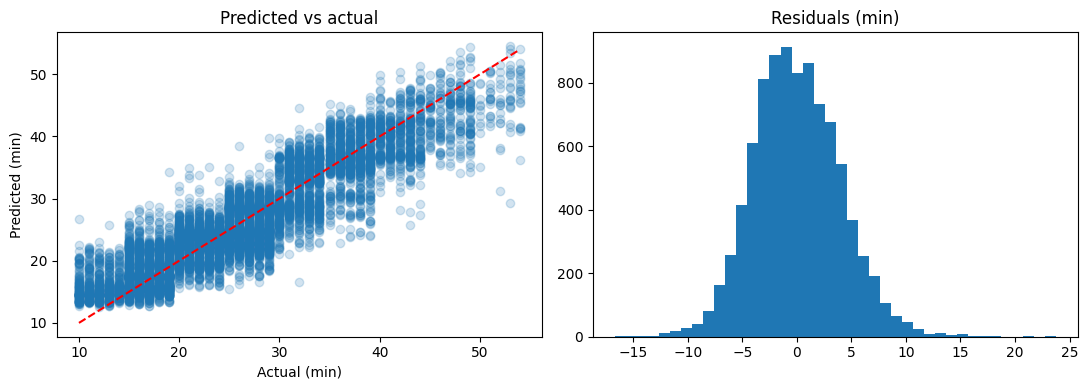

In [6]:
pred = best.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_test, pred, alpha=.2); ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_xlabel("Actual (min)"); ax[0].set_ylabel("Predicted (min)"); ax[0].set_title("Predicted vs actual")
ax[1].hist(y_test - pred, bins=40); ax[1].set_title("Residuals (min)")
plt.tight_layout(); plt.savefig("../figures/model_eval.png", dpi=150); plt.show()

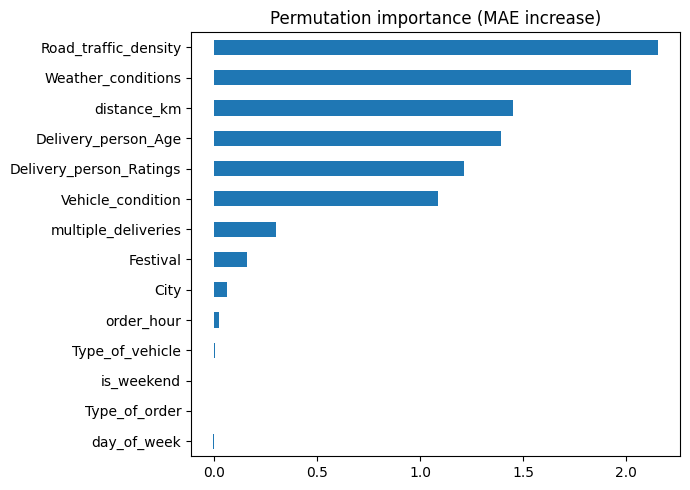

In [7]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(best, X_test.sample(min(len(X_test), 2000), random_state=1),
                             y_test.loc[X_test.sample(min(len(X_test), 2000), random_state=1).index],
                             n_repeats=5, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
imp = pd.Series(imp.importances_mean, index=X.columns).sort_values()
imp.plot.barh(figsize=(7, 5), title="Permutation importance (MAE increase)")
plt.tight_layout(); plt.savefig("../figures/feature_importance.png", dpi=150); plt.show()

## Save model + app options

In [8]:
best.fit(X, y)   # refit on all data for the app
joblib.dump(best, "../models/delivery_time_model.joblib")
options = {c: sorted(X[c].dropna().unique().tolist()) for c in CAT}
options["mae"] = float(results.loc[results.model == "Tuned HGB", "MAE"].iloc[0])
options["age_range"] = [int(X["Delivery_person_Age"].min()), int(X["Delivery_person_Age"].max())]
options["dist_max"] = float(np.ceil(X["distance_km"].quantile(0.99)))
json.dump(options, open("../models/options.json", "w"), indent=2)
options

{'Vehicle_condition': ['0', '1', '2', '3'],
 'multiple_deliveries': ['0', '1', '2', '3'],
 'is_weekend': ['0', '1'],
 'day_of_week': ['Friday',
  'Monday',
  'Saturday',
  'Sunday',
  'Thursday',
  'Tuesday',
  'Wednesday'],
 'Weather_conditions': ['Cloudy',
  'Fog',
  'Sandstorms',
  'Stormy',
  'Sunny',
  'Windy'],
 'Road_traffic_density': ['High', 'Jam', 'Low', 'Medium'],
 'Type_of_order': ['Buffet', 'Drinks', 'Meal', 'Snack'],
 'Type_of_vehicle': ['bicycle', 'electric_scooter', 'motorcycle', 'scooter'],
 'Festival': ['No', 'Yes'],
 'City': ['Metropolitian', 'Semi-Urban', 'Urban'],
 'mae': 3.16,
 'age_range': [15, 50],
 'dist_max': 21.0}